In [9]:
import matplotlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
import os

In [2]:
def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

In [3]:
def applyCut(inputDataframe, cut):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    return cutDataframe

In [4]:
def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['ws'])
        nss = sum(df[df.bs==+1]['ws'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(df[(df.w == w_array[i]) & (df.b==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])
        elif (ob == 'b_ch'):
            p = sum(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])            
        elif (ob == 'bs'):
            p = sum(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) / sum(df[df.w == w_array[i]]['ws'])
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    rc_err = 2*np.sqrt(sum(err2_array))
    return rc, rc_err

In [5]:
def calc_hist(vals, bins=10, weights=None, density=True):
    
    if weights is None:
        weights = np.ones(vals.shape)
    
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    digits = np.digitize(vals, bins)
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])

    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
        
    return hist, errs, bins

In [6]:
plt.rcParams['font.size'] = 15

In [38]:
#observables = ['centrality','rho','jet_pt','jet_eta','jet_phi','jet_area','jet_neutral_fraction',\
#    'jet_leading_track_pt','jet_leading_track_y','jet_leading_track_phi','jet_leading_track_charge',\
#    'jet_subleading_track_pt','jet_subleading_track_y','jet_subleading_track_phi','jet_subleading_track_charge',\
#    'jet_leading_particle_pt','jet_leading_particle_y','jet_leading_particle_phi','jet_leading_particle_charge',\
#    'jet_subleading_particle_pt','jet_subleading_particle_y','jet_subleading_particle_phi','jet_subleading_particle_charge']
observables = ['runnumber','centrality','rho','jet_pt','jet_area','jet_neutral_fraction','jet_leading_track_charge',\
    'jet_subleading_track_pt','jet_subleading_track_charge']

In [39]:
filename = '/gpfs/gibbs/project/havener/ys668/other_output/rc/isobar/ht_49run57.root'
#old_filename = '/gpfs/gibbs/project/havener/ys668/other_output/rc/isobar/ht.root'
treename = 'jet_tree'

In [40]:
df = applyCut(getData(observables, filename, treename), 'jet_subleading_track_pt > 0 and jet_neutral_fraction < 0.9')

In [23]:
df_old = applyCut(getData(observables, old_filename, treename), 'jet_subleading_track_pt > 0 and jet_neutral_fraction < 0.9')

In [24]:
print(df.shape[0], df_old.shape[0])

1634730 7471906


In [25]:
print(np.unique(df['runnumber']),np.unique(df_old['runnumber']))

[19118049 19118050 19118051 19118052 19118053 19118054 19118055 19118056
 19118057] [19085038 19085039 19085040 19085041 19085042 19085043 19085044 19085047
 19085048 19085049 19085050 19085051 19085052 19085053 19085054 19085059
 19085060 19085061 19085062 19085063 19086001 19086002 19086003 19086004]


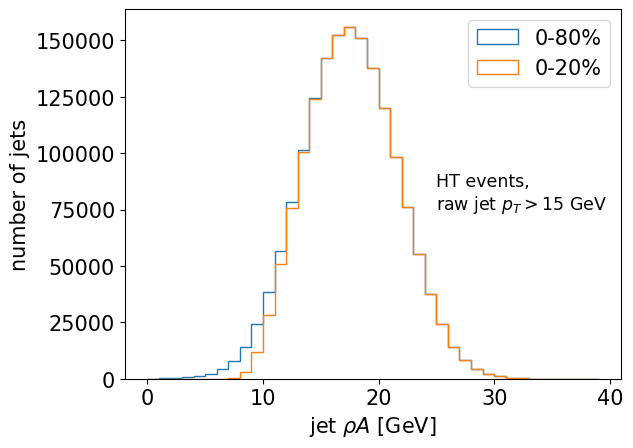

In [44]:
plt.hist(df['rho']*df['jet_area'], bins=np.arange(0,40), histtype='step', label='0-80%')
plt.hist(df[df.centrality>=12]['rho']*df[df.centrality>=12]['jet_area'], bins=np.arange(0,40), histtype='step', label='0-20%')
plt.text(25, 75000, 'HT events,\nraw jet $p_T>15$ GeV', fontsize=12.5)
plt.xlabel(r'jet $\rho A$ [GeV]')
plt.ylabel('number of jets')
plt.legend()

In [50]:
print(np.average(df[df.centrality>=12]['rho']*df[df.centrality>=12]['jet_area']),\
      np.std(df[df.centrality>=12]['rho']*df[df.centrality>=12]['jet_area']))

17.77498 3.832158


In [45]:
def gauss(x, A, x0, sigma): 
    return A * np.exp(-(x - x0) ** 2 / (2 * sigma ** 2))

In [46]:
y, yerr, x = calc_hist(df[df.centrality>=12]['rho']*df[df.centrality>=12]['jet_area'], bins=np.arange(0,40.5,0.5))

In [47]:
x = np.arange(0.5,40.25,0.5)

In [48]:
from scipy.optimize import curve_fit
popt, pcov = curve_fit(gauss, x, y, sigma=yerr)

/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/lib/python3.10/site-packages/scipy/optimize/_minpack_py.py:931: RuntimeWarning: divide by zero encountered in divide
  transform = 1.0 / sigma
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/lib/python3.10/site-packages/scipy/optimize/_minpack_py.py:526: RuntimeWarning: invalid value encountered in multiply
  return transform * (func(xdata, *params) - ydata)


RuntimeError: Optimal parameters not found: Number of calls to function has reached maxfev = 800.

In [49]:
plt.plot(x, gauss(x, *popt), 'r-', label='Guassian fit:\na=%5.1f, b=%5.1f, c=%5.1f' % tuple(popt))
plt.errorbar(x, y, xerr=0.25, yerr=yerr, label='data', color='k', ls='none')
plt.xlabel(r'$\rho A$ [GeV]')
plt.legend(loc='upper right')

NameError: name 'popt' is not defined

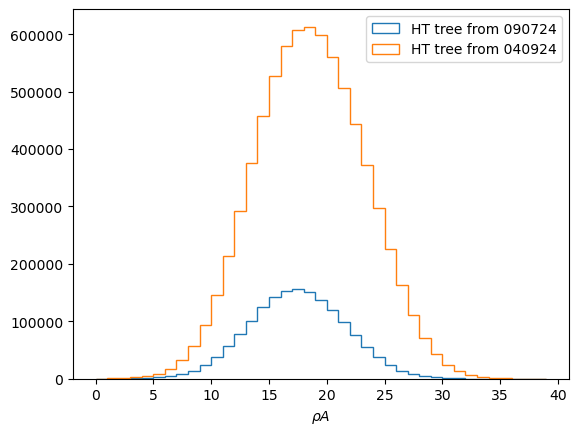

In [20]:
plt.hist(df['rho']*df['jet_area'], bins=np.arange(0,40), histtype='step', label='HT tree from 090724')
plt.hist(df_old['rho']*df_old['jet_area'], bins=np.arange(0,40), histtype='step', label='HT tree from 040924')
plt.xlabel(r'$\rho A$')
plt.legend()

In [63]:
def gauss(x, A, x0, sigma): 
    return A * np.exp(-(x - x0) ** 2 / (2 * sigma ** 2))

In [66]:
y, yerr, x = calc_hist(df['rho']*df['jet_area'], bins=np.arange(0,40.5,0.5))

In [67]:
x = np.arange(0.5,40.25,0.5)

In [68]:
from scipy.optimize import curve_fit
popt, pcov = curve_fit(gauss, x, y, sigma=yerr)

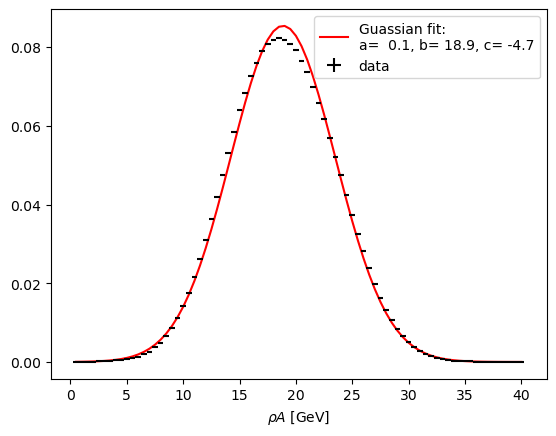

In [76]:
plt.plot(x, gauss(x, *popt), 'r-', label='Guassian fit:\na=%5.1f, b=%5.1f, c=%5.1f' % tuple(popt))
plt.errorbar(x, y, xerr=0.25, yerr=yerr, label='data', color='k', ls='none')
plt.xlabel(r'$\rho A$ [GeV]')
plt.legend(loc='upper right')

In [16]:
df.eval('b_ch = jet_leading_track_charge * jet_subleading_track_charge', inplace=True) 
df.eval('jet_pt_sub = jet_pt - rho * jet_area', inplace=True)
df['w'] = np.ones(df.shape[0])

In [17]:
df_central = applyCut(df, 'centrality >= 11 and b_ch!=0')
df_peripheral = applyCut(df, '0 <= centrality <= 5 and b_ch!=0')

In [19]:
df_central_hc = applyCut(df_central, 'jet_subleading_track_pt > 2')

In [20]:
df_central_hc_array = [ df_central_hc[(df_central_hc.jet_pt>15) & (df_central_hc.jet_pt<20)],\
                       df_central_hc[(df_central_hc.jet_pt>20) & (df_central_hc.jet_pt<25)],\
                       df_central_hc[(df_central_hc.jet_pt>25) & (df_central_hc.jet_pt<30)],\
                       df_central_hc[(df_central_hc.jet_pt>30) & (df_central_hc.jet_pt<40)] ]

In [21]:
rc_central_hc_array = []
rc_err_central_hc_array = []
for i in range(0, len(df_central_hc_array)):
    rc_central_hc_array.append(getRcAndErr(df_central_hc_array[i], 'b_ch')[0])
    rc_err_central_hc_array.append(getRcAndErr(df_central_hc_array[i], 'b_ch')[1])

In [22]:
print(rc_central_hc_array)
print(rc_err_central_hc_array)

[-0.036004645760743324, -0.052207226381550946, -0.04424045827869418, -0.04437251608145204]
[0.006554429011006827, 0.0049971181456628915, 0.004791756553047472, 0.004521680109783628]


In [24]:
rc_pp_hc_array = np.array([-0.329524369823958, -0.31518870414357353, -0.3132168214090661, -0.3042431537767078])
rc_err_pp_hc_array = np.array([0.0015878628958714723, 0.0031471074370218247, 0.006406830702165019, 0.011684976911908687])

Text(0.5, 1.0, '$p_{\\mathrm{T, lead}}, p_{\\mathrm{T, sublead}} > 2$ GeV')

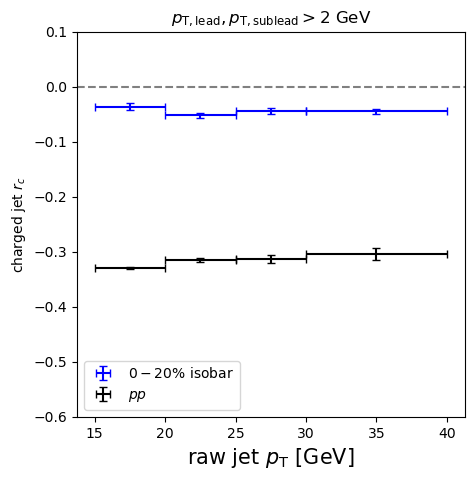

In [25]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35], rc_central_hc_array, xerr=[2.5, 2.5, 2.5, 5], yerr=rc_err_central_hc_array, capsize=3, color='b', ls='none', label='$0-20\%$ isobar')
#plt.errorbar([17.5, 22.5, 27.5, 35], rc_peripheral_array, xerr=[2.5, 2.5, 2.5, 5], yerr=rc_err_peripheral_array, capsize=3, color='r', ls='none', label='$50-80\%$ isobar')
plt.errorbar([17.5, 22.5, 27.5, 35], rc_pp_hc_array, xerr=[2.5, 2.5, 2.5, 5], yerr=rc_err_pp_hc_array, capsize=3, color='k', ls='none', label='$pp$')
plt.xlabel('raw jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='lower left')
plt.title('$p_{\mathrm{T, lead}}, p_{\mathrm{T, sublead}} > 2$ GeV')

In [27]:
df_central_hc = applyCut(df_central, 'jet_subleading_track_pt > 2')

In [37]:
df_peripheral_hc = applyCut(df_peripheral, 'jet_subleading_track_pt > 2')

In [28]:
df_central_hc_array = [ df_central_hc[(df_central_hc.jet_pt_sub>15) & (df_central_hc.jet_pt_sub<20)],\
                       df_central_hc[(df_central_hc.jet_pt_sub>20) & (df_central_hc.jet_pt_sub<25)],\
                       df_central_hc[(df_central_hc.jet_pt_sub>25) & (df_central_hc.jet_pt_sub<30)],\
                       df_central_hc[(df_central_hc.jet_pt_sub>30) & (df_central_hc.jet_pt_sub<40)] ]

In [38]:
df_peripheral_hc_array = [ df_peripheral_hc[(df_peripheral_hc.jet_pt_sub>15) & (df_peripheral_hc.jet_pt_sub<20)],\
                       df_peripheral_hc[(df_peripheral_hc.jet_pt_sub>20) & (df_peripheral_hc.jet_pt_sub<25)],\
                       df_peripheral_hc[(df_peripheral_hc.jet_pt_sub>25) & (df_peripheral_hc.jet_pt_sub<30)],\
                       df_peripheral_hc[(df_peripheral_hc.jet_pt_sub>30) & (df_peripheral_hc.jet_pt_sub<40)] ]

In [29]:
rc_central_hc_array = []
rc_err_central_hc_array = []
for i in range(0, len(df_central_hc_array)):
    rc_central_hc_array.append(getRcAndErr(df_central_hc_array[i], 'b_ch')[0])
    rc_err_central_hc_array.append(getRcAndErr(df_central_hc_array[i], 'b_ch')[1])

In [29]:
rc_central_hc_array = []
rc_err_central_hc_array = []
for i in range(0, len(df_central_hc_array)):
    rc_central_hc_array.append(getRcAndErr(df_central_hc_array[i], 'b_ch')[0])
    rc_err_central_hc_array.append(getRcAndErr(df_central_hc_array[i], 'b_ch')[1])

Text(0.5, 1.0, '$p_{\\mathrm{T, lead}}, p_{\\mathrm{T, sublead}} > 2$ GeV')

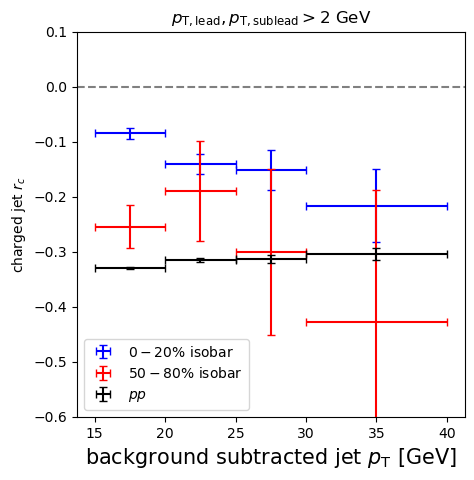

In [41]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35], rc_central_hc_array, xerr=[2.5, 2.5, 2.5, 5], yerr=rc_err_central_hc_array, capsize=3, color='b', ls='none', label='$0-20\%$ isobar')
plt.errorbar([17.5, 22.5, 27.5, 35], rc_peripheral_array, xerr=[2.5, 2.5, 2.5, 5], yerr=rc_err_peripheral_array, capsize=3, color='r', ls='none', label='$50-80\%$ isobar')
plt.errorbar([17.5, 22.5, 27.5, 35], rc_pp_hc_array, xerr=[2.5, 2.5, 2.5, 5], yerr=rc_err_pp_hc_array, capsize=3, color='k', ls='none', label='$pp$')
plt.xlabel('background subtracted jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='lower left')
plt.title('$p_{\mathrm{T, lead}}, p_{\mathrm{T, sublead}} > 2$ GeV')

In [47]:
observables1 = ['pt','b','pt2']

In [49]:
file = uproot.open('/home/ys668/project/other_output/rc/data0613_chargedrc.root')
tree = file["ResultTree"].arrays(observables1, library='np')
#array = []
#for observable in observables1:
#    array.append(np.concatenate(tree[observable]))
df_pp = pd.DataFrame(np.transpose(np.array((np.concatenate(tree['pt']),np.concatenate(tree['b']),np.concatenate(tree['pt2'])))),\
                     columns=["pts","bs","pt2s"])
df_pp = applyCut(df_pp, 'pts>15 and bs!= -9')

In [50]:
df_pp['w'] = np.ones(df_pp.shape[0])
df_pp['ws'] = np.ones(df_pp.shape[0])

In [51]:
df_pp_array = [ df_pp[(df_pp.pts>15) & (df_pp.pts<20)],\
                       df_pp[(df_pp.pts>20) & (df_pp.pts<25)],\
                       df_pp[(df_pp.pts>25) & (df_pp.pts<30)],\
                       df_pp[(df_pp.pts>30) & (df_pp.pts<40)] ]

In [52]:
rc_pp_array = []
rc_err_pp_array = []
for i in range(0, len(df_pp_array)):
    rc_pp_array.append(getRcAndErr(df_pp_array[i], 'bs')[0])
    rc_err_pp_array.append(getRcAndErr(df_pp_array[i], 'bs')[1])

In [54]:
df_pp_hc = applyCut(df_pp, 'pt2s > 2')

In [55]:
df_pp_hc_array = [ df_pp_hc[(df_pp_hc.pts>15) & (df_pp_hc.pts<20)],\
                       df_pp_hc[(df_pp_hc.pts>20) & (df_pp_hc.pts<25)],\
                       df_pp_hc[(df_pp_hc.pts>25) & (df_pp_hc.pts<30)],\
                       df_pp_hc[(df_pp_hc.pts>30) & (df_pp_hc.pts<40)] ]

In [58]:
rc_pp_hc_array = []
rc_err_pp_hc_array = []
for i in range(0, len(df_pp_hc_array)):
    rc_pp_hc_array.append(getRcAndErr(df_pp_hc_array[i], 'bs')[0])
    rc_err_pp_hc_array.append(getRcAndErr(df_pp_hc_array[i], 'bs')[1])

In [53]:
print(rc_pp_array)
print(rc_err_pp_array)

[-0.3087933449476, -0.3049137767841851, -0.30877555891479036, -0.2980493793479744]
[0.0013247772219597514, 0.002859432635262245, 0.005998971104851678, 0.011148521567582732]


In [59]:
print(rc_pp_hc_array)
print(rc_err_pp_hc_array)

[-0.329524369823958, -0.31518870414357353, -0.3132168214090661, -0.3042431537767078]
[0.0015878628958714723, 0.0031471074370218247, 0.006406830702165019, 0.011684976911908687]
